# Optimización sin restricciones
**Métodos Numéricos · Universidad del Pacífico · 2026-2**

Laboratorio de la sección 9.2. El objetivo es comparar el descenso del gradiente
con paso fijo, retroceso de Armijo y búsqueda de Powell–Wolfe (Wolfe débil).
Ejecuta el cuaderno de arriba abajo en Jupyter o Colab. Solo requiere NumPy y Matplotlib.

En cada iteración usamos $x_{k+1}=x_k+alpha_k p_k$, con $p_k=-g_k$ y
$g_k=
abla f(x_k)$. Detenemos el método cuando $|g_k|_2learepsilon$
o se agota el presupuesto. La primera condición mide estacionariedad.
Para una función convexa diferenciable, el gradiente nulo caracteriza
un mínimo global.

En el ajuste de demanda conocemos el óptimo y las constantes $mu,L$.
En Rosenbrock conocemos el óptimo, pero la función no satisface las hipótesis
globales del teorema de paso fijo.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

COLORES = {"Fijo": "#003B70", "Armijo": "#AB7708", "Powell–Wolfe": "#167C5A"}

## 1. Geometría de la búsqueda lineal

En una iteración, $phi(alpha)=f(x+alpha p)$ y
$phi'(alpha)=
abla f(x+alpha p)^	op p$, con $phi'(0)<0$.
Armijo acepta un paso positivo si
$$phi(alpha)lephi(0)+c_1alphaphi'(0).$$
El retroceso empieza en un paso de prueba y lo multiplica por
$0<
ho<1$ hasta satisfacer la desigualdad.

Powell–Wolfe añade $phi'(alpha)ge c_2phi'(0)$, con $0<c_1<c_2<1$.
Esta segunda condición descarta pasos en los que la pendiente aún es
demasiado negativa. La prueba admite una pendiente positiva siempre que
el paso cumpla Armijo.

Usamos el mismo perfil que en la presentación,
$phi(alpha)=(alpha-1)^2$. Con $c_1=0.2$ y $c_2=0.5$, Armijo
acepta $0<alphale1.6$ y Powell–Wolfe acepta $0.5lealphale1.6$.
Estos valores de $c_1,c_2$ hacen visible el intervalo en el gráfico.

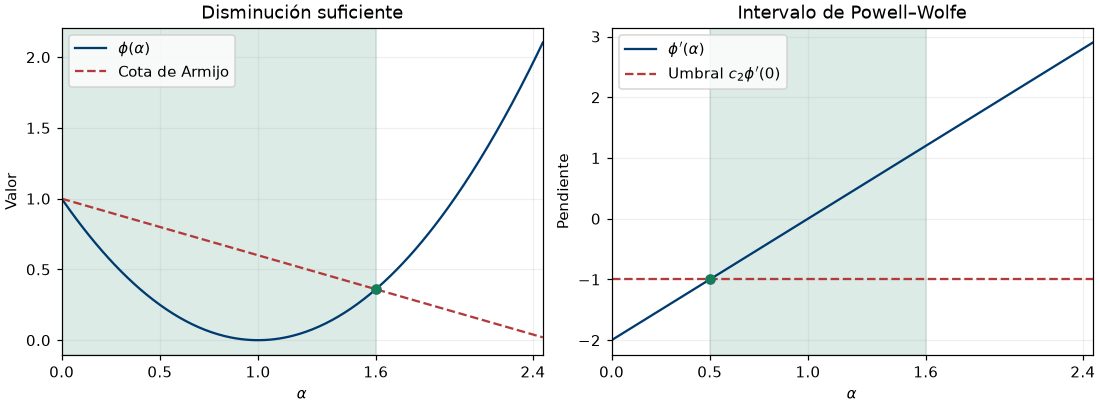

In [2]:
pasos = np.linspace(0, 2.45, 300)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")

ax1.plot(pasos, (pasos - 1)**2, color=COLORES["Fijo"], label=r"$\phi(\alpha)$")
ax1.plot(pasos, 1 - 0.4*pasos, "--", color="#B33A3A", label="Cota de Armijo")
ax1.axvspan(0, 1.6, color=COLORES["Powell–Wolfe"], alpha=0.15)
ax1.scatter(1.6, 0.36, color=COLORES["Powell–Wolfe"], zorder=3)
ax1.set(ylabel="Valor", title="Disminución suficiente")

ax2.plot(pasos, 2*(pasos - 1), color=COLORES["Fijo"], label=r"$\phi'(\alpha)$")
ax2.axhline(-1, ls="--", color="#B33A3A", label=r"Umbral $c_2\phi'(0)$")
ax2.axvspan(0.5, 1.6, color=COLORES["Powell–Wolfe"], alpha=0.15)
ax2.scatter(0.5, -1, color=COLORES["Powell–Wolfe"], zorder=3)
ax2.set(ylabel="Pendiente", title="Intervalo de Powell–Wolfe")

for ax in (ax1, ax2):
    ax.set(xlabel=r"$\alpha$", xlim=(0, 2.45), xticks=[0, 0.5, 1, 1.6, 2.4])
    ax.grid(alpha=0.2)
    ax.legend(loc="upper left")
plt.show()

## 2. Implementación de los tres métodos

En Armijo se reduce el paso cada vez que falla la prueba. En Powell–Wolfe,
si el candidato cumple Armijo y falla curvatura, lo guardamos como extremo
inferior y expandimos el paso. Cuando una prueba falla Armijo ya tenemos
un extremo superior y continuamos por bisección. Al empezar, el extremo
inferior puede ser $0$.

En los experimentos usamos $aralpha=1$, $
ho=1/2$, $c_1=10^{-4}$
y $c_2=0.5$. Las búsquedas tienen un máximo de 60 pruebas. Si lo agotan,
el método devuelve el último iterado válido e informa el fallo.

In [3]:
def armijo(f, grad, x, fx, p, m0, alpha=1.0, rho=0.5, c1=1e-4, max_pruebas=60):
    for _ in range(max_pruebas):
        valor = f(x + alpha*p)
        if np.isfinite(valor) and valor <= fx + c1*alpha*m0:
            return alpha, valor, None
        alpha *= rho
    raise RuntimeError("Armijo agotó las pruebas")


def powell_wolfe(f, grad, x, fx, p, m0, alpha=1.0, c1=1e-4, c2=0.5,
                 max_pruebas=60):
    inferior, superior = 0.0, None
    for _ in range(max_pruebas):
        candidato = x + alpha*p
        valor = f(candidato)
        if np.isfinite(valor) and valor <= fx + c1*alpha*m0:
            g_nuevo = grad(candidato)
            pendiente = g_nuevo @ p
            if not np.isfinite(pendiente):
                raise RuntimeError("Pendiente no finita en Powell–Wolfe")
            if pendiente >= c2*m0:
                return alpha, valor, g_nuevo
            inferior = alpha
        else:
            superior = alpha

        if superior is None:
            alpha *= 2
        else:
            alpha = (inferior + superior)/2
            if not inferior < alpha < superior:
                break
    raise RuntimeError("Powell–Wolfe no encontró un paso en el intervalo")

In [4]:
def descenso(f, grad, x0, paso, *, tol=1e-6, max_iter=1000):
    # paso es una constante positiva o una función de búsqueda lineal.
    n_f, n_g = 0, 0

    def evaluar_f(x):
        nonlocal n_f
        n_f += 1
        return f(x)

    def evaluar_grad(x):
        nonlocal n_g
        n_g += 1
        return grad(x)

    x = np.array(x0, dtype=float)
    fx, g = evaluar_f(x), evaluar_grad(x)
    trayectoria, valores, normas, pasos = [x], [fx], [np.linalg.norm(g)], []
    estado = "límite de iteraciones"

    for k in range(max_iter + 1):
        if normas[-1] <= tol:
            estado = "tolerancia"
            break
        if k == max_iter:
            break

        p = -g
        if callable(paso):
            try:
                alpha, f_nuevo, g_nuevo = paso(evaluar_f, evaluar_grad, x, fx, p, g @ p)
            except RuntimeError as error:
                estado = str(error)
                break
        else:
            alpha = paso
            f_nuevo, g_nuevo = evaluar_f(x + alpha*p), None

        candidato = x + alpha*p
        if g_nuevo is None:
            g_nuevo = evaluar_grad(candidato)
        if not (np.isfinite(f_nuevo) and np.all(np.isfinite(g_nuevo))):
            estado = "evaluación no finita"
            break
        if np.array_equal(candidato, x):
            estado = "paso indistinguible de cero"
            break

        x, fx, g = candidato, f_nuevo, g_nuevo
        trayectoria.append(x)
        valores.append(fx)
        normas.append(np.linalg.norm(g))
        pasos.append(alpha)

    return {"x": np.array(trayectoria), "f": np.array(valores),
            "norma_g": np.array(normas), "alpha": np.array(pasos),
            "n_f": n_f, "n_g": n_g, "estado": estado}


def comparar(f, grad, x0, paso_fijo, max_iter, tol=1e-6):
    reglas = {"Fijo": paso_fijo, "Armijo": armijo, "Powell–Wolfe": powell_wolfe}
    return {nombre: descenso(f, grad, x0, paso, tol=tol, max_iter=max_iter)
            for nombre, paso in reglas.items()}


def resumen(resultados, f_estrella):
    print(f"{'Método':<14} {'Iter.':>6} {'Eval. f':>8} {'Eval. grad':>10}"
          f" {'Brecha':>11} {'Norma grad':>12}  Estado")
    for nombre, r in resultados.items():
        brecha = r["f"][-1] - f_estrella
        print(f"{nombre:<14} {len(r['alpha']):>6} {r['n_f']:>8} {r['n_g']:>10}"
              f" {brecha:>11.3e} {r['norma_g'][-1]:>12.3e}  {r['estado']}")

## 3. Demanda y convergencia con paso fijo

Cinco pares simulados de precio y cantidad sirven para ajustar
$widehat Q(P)=a+b(P-10)$. Con $A_i=(1,P_i-10)$ y $	heta=(a,b)$,
$$
f(	heta)=rac{1}{10}|A	heta-Q|^2,quad

abla f(	heta)=rac{A^	op(A	heta-Q)}{5},quad
H=rac{A^	op A}{5}.
$$
La regresión por mínimos cuadrados da un valor de referencia para el experimento.
Una unidad adicional de precio se asocia con $3.6$ unidades menos de demanda
en el modelo ajustado. Los datos son simulados.

In [5]:
P = np.array([6, 8, 10, 12, 14], dtype=float)
Q = np.array([63, 53, 49, 43, 32], dtype=float)
A = np.column_stack((np.ones(P.size), P - 10))
H = A.T @ A / P.size
mu, L = np.linalg.eigvalsh(H)
theta_star = np.linalg.lstsq(A, Q, rcond=None)[0]

def f_demanda(theta):
    residuo = A @ theta - Q
    return (residuo @ residuo)/(2*P.size)

def grad_demanda(theta):
    return A.T @ (A @ theta - Q)/P.size

alpha_wegner = 2/(mu + L)
q = (L - mu)/(L + mu)
print(f"μ={mu:g}, L={L:g}, κ={L/mu:g}, α={alpha_wegner:.6f}, q={q:.6f}")
print(f"Ajuste de referencia: a={theta_star[0]:g}, b={theta_star[1]:g}")

x0_demanda = np.array([44., -1.])
res_demanda = comparar(f_demanda, grad_demanda, x0_demanda, alpha_wegner, max_iter=250)
resumen(res_demanda, f_demanda(theta_star))

μ=1, L=8, κ=8, α=0.222222, q=0.777778
Ajuste de referencia: a=48, b=-3.6
Método          Iter.  Eval. f Eval. grad      Brecha   Norma grad  Estado
Fijo               68       69         69   5.351e-14    8.019e-07  tolerancia
Armijo             13       39         14   3.331e-15    8.527e-14  tolerancia
Powell–Wolfe       13       39         14   3.331e-15    8.527e-14  tolerancia


El teorema de Wegner usa $alpha=2/(mu+L)$ y
$q=(L-mu)/(L+mu)$. Predice $|	heta_k-	heta^*|le q^k|	heta_0-	heta^*|$.
En este ejemplo se alcanza la cota en aritmética exacta. En las dos
direcciones propias, $I-alpha H$ multiplica el error por $q$ y por $-q$.
La recta punteada negra representa la predicción teórica. Con estos parámetros
y este punto inicial, Armijo y Powell–Wolfe aceptan los mismos pasos. Sus
curvas se superponen.

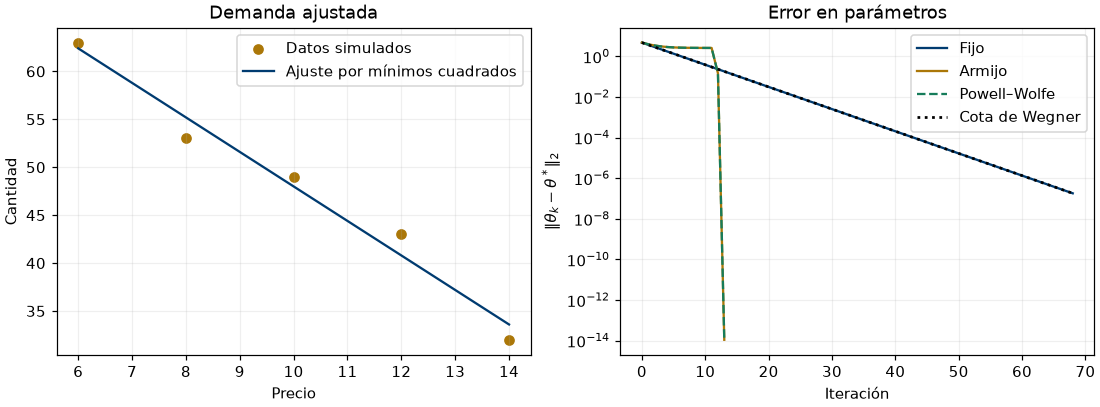

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.7), layout="constrained")

precios = np.linspace(P.min(), P.max(), 100)
ax1.scatter(P, Q, color=COLORES["Armijo"], label="Datos simulados")
ax1.plot(precios, theta_star[0] + theta_star[1]*(precios-10),
         color=COLORES["Fijo"], label="Ajuste por mínimos cuadrados")
ax1.set(xlabel="Precio", ylabel="Cantidad", title="Demanda ajustada")

for nombre, r in res_demanda.items():
    error = np.linalg.norm(r["x"] - theta_star, axis=1)
    estilo = "--" if nombre == "Powell–Wolfe" else "-"
    ax2.semilogy(error, estilo, label=nombre, color=COLORES[nombre])
k_fijo = np.arange(len(res_demanda["Fijo"]["x"]))
ax2.semilogy(k_fijo, np.linalg.norm(x0_demanda-theta_star)*q**k_fijo,
             "k:", lw=1.8, label="Cota de Wegner")
ax2.set(xlabel="Iteración", ylabel=r"$\|\theta_k-\theta^*\|_2$", title="Error en parámetros")
for ax in (ax1, ax2):
    ax.grid(alpha=0.2)
    ax.legend()
plt.show()

## 4. Rosenbrock

El cuaderno base propone $f(x,y)=(1-x)^2+100(y-x^2)^2$,
cuyo mínimo global es $0$ en $(1,1)$. Conservamos el punto inicial
$(-1.2,1)$ y el paso fijo de prueba $10^{-3}$. Las tres reglas usan la misma
tolerancia y un máximo de 1000 iteraciones. El resumen distingue haber
alcanzado la tolerancia de haber agotado el presupuesto.

In [7]:
def rosenbrock(x):
    x1, x2 = x
    return (1 - x1)**2 + 100*(x2 - x1**2)**2

def grad_rosenbrock(x):
    x1, x2 = x
    d1 = -2*(1 - x1) - 400*x1*(x2 - x1**2)
    d2 = 200*(x2 - x1**2)
    return np.array([d1, d2])

x0_rosen = np.array([-1.2, 1.0])
res_rosen = comparar(rosenbrock, grad_rosenbrock, x0_rosen, 1e-3, max_iter=1000)
resumen(res_rosen, 0.0)

Método          Iter.  Eval. f Eval. grad      Brecha   Norma grad  Estado
Fijo             1000     1001       1001   4.535e-01    1.126e+00  límite de iteraciones
Armijo           1000     9834       1001   7.484e-04    7.390e-02  límite de iteraciones
Powell–Wolfe     1000     9883       1002   3.371e-04    2.367e-02  límite de iteraciones


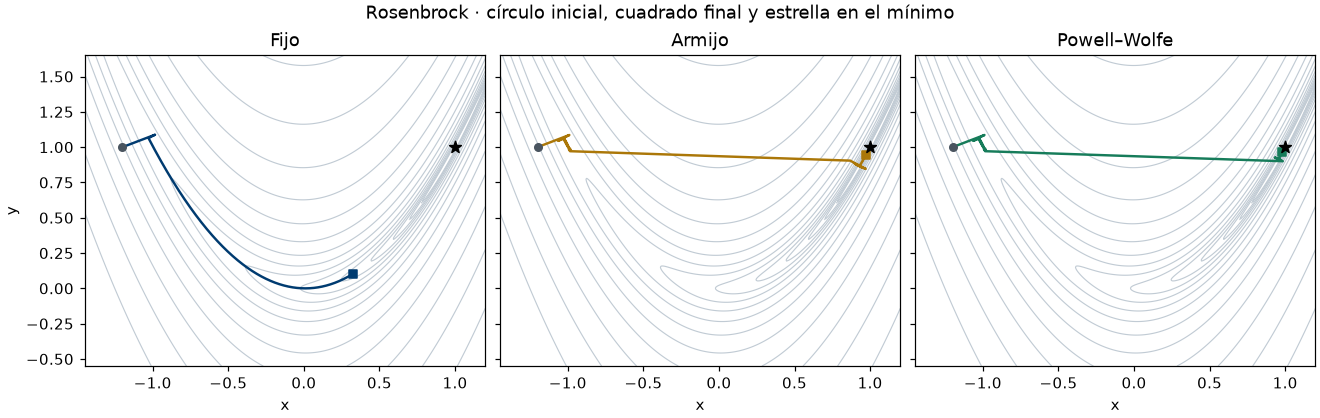

In [8]:
xs, ys = np.linspace(-1.45, 1.2, 360), np.linspace(-0.55, 1.65, 300)
X, Y = np.meshgrid(xs, ys)
Z = rosenbrock((X, Y))
niveles = np.geomspace(0.05, 250, 15)
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), layout="constrained",
                         sharex=True, sharey=True)
for ax, (nombre, r) in zip(axes, res_rosen.items()):
    puntos = r["x"]
    ax.contour(X, Y, Z, levels=niveles, colors="#C1CBD4", linewidths=0.75)
    ax.plot(*puntos.T, color=COLORES[nombre], lw=1.6)
    ax.scatter(*puntos[0], marker="o", color="#4A5560", s=24, zorder=3)
    ax.scatter(*puntos[-1], marker="s", color=COLORES[nombre], s=28, zorder=4)
    ax.scatter(1, 1, marker="*", color="black", s=65, zorder=5)
    ax.set(xlabel="x", title=nombre, xlim=(xs[0], xs[-1]), ylim=(ys[0], ys[-1]))
axes[0].set_ylabel("y")
fig.suptitle("Rosenbrock · círculo inicial, cuadrado final y estrella en el mínimo")
plt.show()

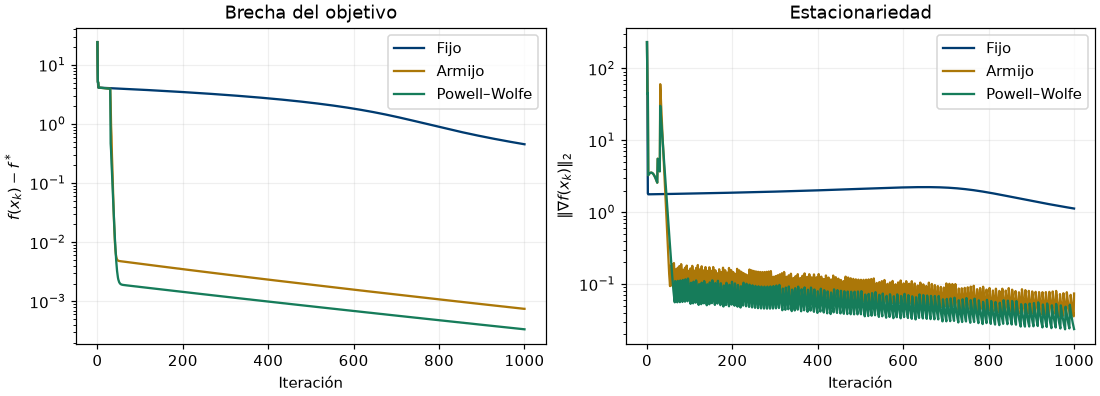

In [9]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
for nombre, r in res_rosen.items():
    ax1.semilogy(r["f"], color=COLORES[nombre], label=nombre)
    ax2.semilogy(r["norma_g"], color=COLORES[nombre], label=nombre)
ax1.set(xlabel="Iteración", ylabel=r"$f(x_k)-f^*$", title="Brecha del objetivo")
ax2.set(xlabel="Iteración", ylabel=r"$\|\nabla f(x_k)\|_2$", title="Estacionariedad")
for ax in (ax1, ax2):
    ax.grid(alpha=0.2)
    ax.legend()
plt.show()

## 5. Ejercicios

1. En el perfil unidimensional, verifica las dos condiciones para
   $alpha=0.25$, $1.2$ y $2.4$. Repite el gráfico con $c_2=0.9$ y calcula
   el nuevo extremo inferior del intervalo de Powell–Wolfe.
2. En el ajuste de demanda, compara $alpha=1/L$, $alpha=2/(mu+L)$ y
   $alpha=2/L$. Explica el comportamiento del coeficiente $b$ usando
   el factor $1-alpha L$. Calcula la elasticidad precio puntual
   $bP/widehat Q(P)$ para $P=10$.
3. En Rosenbrock, compara el orden de los métodos por brecha final y por
   número de evaluaciones de función y gradiente. Repite con otro valor
   de $c_2$ manteniendo el mismo punto inicial y presupuesto.

### Referencias

- [Sven-Ake Wegner, *Mathematische Einführung in Data Science*, capítulo 17](https://doi.org/10.1007/978-3-662-68697-3).
- [L. Armijo (1966), *Minimization of functions having Lipschitz continuous first partial derivatives*](https://doi.org/10.2140/pjm.1966.16.1).
- [P. Wolfe (1969), *Convergence Conditions for Ascent Methods*](https://doi.org/10.1137/1011036).
- Material de clase de partida de Oswaldo Velásquez Castañón, `optinum.pdf`
  y `Optimizacion_Descenso_Gradiente.ipynb`.